<a href="https://colab.research.google.com/github/FedericoIeraci-cell/Alerta-Litoral/blob/main/goya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json, base64, gzip, hashlib, urllib.request, re, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
%matplotlib inline

print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| matplotlib:', matplotlib.__version__)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

Python: 3.13.18
pandas: 2.2.3 | numpy: 2.4.6 | matplotlib: 3.10.0


In [2]:
MODO = 'captura_verificada'  # Alternativa: 'api'
ZONA = 'America/Argentina/Buenos_Aires'
INICIO = '2015-12-01'
FIN_EXCLUSIVO = '2016-02-01'
URL = 'https://alerta.ina.gob.ar/a5/getSeriesBySiteAndVar?series_id=23&tipo=puntual&timestart=2015-12-01&timeend=2016-02-01&includeProno=false'
FECHA_DESCARGA_CAPTURA = '2026-11-08T18:44:24.454878+00:00'
SHA256_CAPTURA = '0b4b8c854551a7dbeba4837d3369858a9a7e161d1983fac3239320e9bb84cd92'
# Bytes de la respuesta real del INA, comprimidos sin modificar su contenido.
CAPTURA_GZIP_BASE64 = 'H4sIAAAAAAACA4Xb0W7juBUG4FcJfJ0YIilSZO6C6e52gG5mMJO22F0MAsVWEhW2Zchy2mCQB+p1H2FfrEeOkxF5+B8Dc2GL8iea/GVzeOLvs6HddrPL2Xa/Gfb1anY+a5ezS23OZ81uqBdtt5ldfn8/tunWd31Dp//SPdeHc2+b/wxNvxkJVRV06KHp1uNLhufteOLnrt0MdHjRdf2y3dRDs5td/nFhw1xXpjDB6vMLHeaqNJXzZfnt5Xw21Herml5ar4Z9X+9ut31z3xCx7bundrNox7YPn758+fjT9c1PX8eGuiV0dtU/NJuBrkGH+nbs0eerL1fXVx+vf6YjjyR1d3Te0O+b87e3/VdqqfdDt66HdkHwfb3aNePJd+2qHer+7XS69rZt6MCre301vo6G4qmtx06OI/Lpt/HgqlvUq3ZZ04Bt9qsV9aShUT0qm/apWd3Wq6Yf6CV2rt8ONU/1Yn8cbTuv3s982FOv7+p/1dRvPR9ngAalHfbv+nZ/t2oXb/6i6bvb9oEQGlJXjRdfvk2fKo4jezs+Y4P7PrPNjt5AvTv7PDYsxpPOrg89O4Tj7XrHcXp9evvYErSqhx8DWC8WzW53u2robRD6774dmtkLTe7TOKbHQB2fHSbh/fpXh46dPbbLvlv/+d+hH+flONjv/aYDx3xt9mt6sqRrHw986MYM7Lv9bjb6q31zbPi5bVbLs093u6Z/otmmoT6f/dJsmr5efaBYPnT989iXZ7ruqnt4ptZ/0HTTiDXX9fqQ+fqhOXts2ofHMdBf6/V21fzaLFvqweXs676/rxfN2T+J6sceNfe3+007vI62UmOP23Xzdb/ddv0wDsFzU/c0rTQta+ry4+vDZf38+uCx27+10rs53DX0eNcsus3y7fhq1f448PJ6zceur28XdInmNSIvh+wuqJvrlu6O7j0OkyFfU+ui/fN/m7Nl29OcT8f7te0wWEuKRt9uX1M6+5W9iC5F75iiP3b2eJX4MkPf7aY2Pf47jdHu418o9vr45OZ1uv7WbB6GxxG931PH6dD3l8NEN7d9vXloDp8xNKL0KTWO50yFwlwU7kJVN0pdKndZ+nlRFL8fB77ZjPOgC01nqIuiuinMZVHQv7eTFh19AtIppXPBj5ftXpMyvt3DZ9Yf9GplL5S+KNRNUcWvxk12bjy1K6crVyhfmtm38wmlMaU5VZopVcaUwZThlJ1KNpZKLJUZKeqUiymLKZuh3JSqYsphymWoMKV8TFWYqjjl9JQKMeUx5U9QtoipgKlwilIRpQpI8SZ7+Kr4QemYwmFXmbC7adhtHHaFw670KSoOu8JhV+YUFadd4bSrTNrdNFc2TrvCaVeZtFfRDMZpVzjtKpP2anoP2jjtCqddZdJeRWGI065w2lUm7V5NKBenXeG0q0za/fSTwcVp1zjtOpP2MB0rF6dd47TzpqhLcdQ1jjpvcvMi6lIcdY2jzpuImkbdxVHXOOq8yc31NJ8ujrrGUedNbm6iNxhHXeOo8yaipvl0cdQ1jjpvcvE3s4ujrnHUeZObl9OxquKoaxx13pRScdQNjjpvImoa0SqOusFR501pr97T7mjJAxZEoImoqVTGksZS5r4x0fuzMWUwlblvTPT+XEyVN0oDijXRfRP1qmKUxZQVKc8ojymfUtMVXxVSSitIJU0J5YuYoru/ABRrSinFKIMpI1KaUQ5TTqQMowKmgkiVKQVzZTO5mt443jLKYsqKlGOUxxTL1fRL3idpdzgMLhOGiPKMMpgyIhUY5TDlJCoUjAqYCiKlUgqGwWXCMJU0kyyWrCQZJnkspVFQ07VxKFMKfsQ4/hGjpl/NIcl6hVNV8VSp6YIhOEYZTKWpUtOP41AxymHKiZRnVMBUEKmQUjBVFU/VlApFwSiLKStSilEeU16kdErBXFWZXEVUknaPc+UzuYqoklEGU0akLKMcppxIOUYFTAWRqlIK5sqfypVnlMWUnKvAKI8pMVeqSCmYK38iVypJe8C5CidypTSjDKbEXCnDKIcpMVeqZFTAlJgrZVMK5ipkclVNKccoiykrUhWjPKa8SPmUgrkKmVxFVJz2cSsP5Io3JZQuGGUwZYRv56AVoxymnEhpRgVMBZEyKYVyxZtSqmSUxZQVFkVBW0Z5THmRcimFcsWbUipO+7ivi3Kl5FV70J5RBlNGpAKjHKakVXswBaMCpoJIqZSCuVKZVXtEaUZZTFmRMozymPLCRl8wZUrBXKnM1kBEJWnXOFc6kyszpRyjDKaM8N/dYCpGOUxJWwPBeEYFTAWRCikFc6UzuZpSZcEoiykrUopRHlNepHRKwVxpecsplEnaDc6VkbecQlkyymDKCNtzobSMcphyIuUYFTAVRKpKKZgrI29lhtIzymKK5Wr6lVoGRnlMsVxNv7xskvYSz2DJZ3D6GWMVkxyWnCRpJgUsBUkyqQSnL7MTHUklkyyWrCRZJnkseUlyqQQ/EzLb0JGUxBzvQqvMLnQkeSYZLIl5CkxyWJLy5AomBSxJeXIqlWCerJwnl2TcwXKLylXxpqsXl4S8wlQl1xaDS1LuMZWp4pnpOsElMQ+YCqeoOOf5gjVoSqk46BqvP3Vm/RmPlWeUx5QXZzCkFLqRdWbRGFFVnHWNF41ay3dypZhksCTdyZVmksOSk76uktKpxktGnVsyRlSZUjAKuSVjRFlGWUxZkXKM8pgSv9qT2qnGS0adWzJGVJJ1vGTUuSVjRAVGGUwZiUpqp/m/zwBNKZWEHX+w61xpcbo3lNRONS4t6lxpMaJMSsEZtJkZjKgk7bi0qHOlxYiyjDKYMiLlGOUw5USqYlTAVBApn1IwDO5UGAKjLKbEMCS1U42LizpTXIwplVIwV+5ErpLiqcbFRV2dyFVSPdW4uKirE7lKqqcaFxd1dSJXSfVU4+Kirk7kKqmealxc1NWJXCXVU42Li7o6lSufUjAMmYpg9F/cpHqqcUVQZyqCE0oXSfVU44qg9uLOAlGKUQ5TTqQ0owKmgkiZlIJh8OKOFVEloyymrEhZRnlMeZFyKQVz5cUdK6KStOOKoA7ijhVRnlEGU0akAqMcppxEJdVTjSuCOog7oXSaSimYq0xFcLJrTKdpRllMWZEyjPKY8iJVphTMVaYiGFNx2g2uCJpC3GEfT2OUwZQRqYpRDlNOpDyjAqaCSIWUQrkymYrgpLChi6R6anBF0GQqgjGlGOUxJfzxHVE6pVCuTKYiGFNx2g2uCBq5IkhUySiDKQP/OI0kyySHJSdJjkkBS0GSqlSCoVLSH/GR5JlksWQlKTDJY8kLUlI3NXhbx+RqgVOJYv7tfLZt+sX4I91Vs7vtm/vxR3z28JPX8UalR+X441dbzC7N4RcflR0fkUNr2MMPYF9e/g+dGAkBsjwAAA=='

In [3]:
captura = gzip.decompress(base64.b64decode(CAPTURA_GZIP_BASE64))
assert hashlib.sha256(captura).hexdigest() == SHA256_CAPTURA, 'La captura fue modificada.'
if MODO == 'captura_verificada':
    contenido = captura
    fecha_descarga = FECHA_DESCARGA_CAPTURA
elif MODO == 'api':
    # Un error del servicio se muestra; no se sustituye por datos simulados ni otra fuente.
    peticion = urllib.request.Request(URL, headers={'User-Agent': 'TPI-Goya-EDA/1.0'})
    with urllib.request.urlopen(peticion, timeout=45) as respuesta:
        assert respuesta.status == 200
        contenido = respuesta.read()
    fecha_descarga = datetime.now(timezone.utc).isoformat()
else:
    raise ValueError('Usar captura_verificada o api.')

fuente = json.loads(contenido)
assert fuente['tipo'] == 'puntual' and fuente['id'] == 23
assert fuente['estacion']['nombre'].strip().lower() == 'goya'
assert fuente['estacion']['propietario'] == 'PNA'
assert fuente['var']['id'] == 2 and fuente['var']['valuetype'] == 'Field Observation'
assert fuente['procedimiento']['nombre'].lower() == 'medición directa'
assert fuente['unidades']['abrev'] == 'm'
assert isinstance(fuente.get('observaciones'), list) and fuente['observaciones']
assert all(isinstance(fila, list) and len(fila) == 4 for fila in fuente['observaciones'])
huella = hashlib.sha256(contenido).hexdigest()
salidas = Path('salidas_goya')
salidas.mkdir(exist_ok=True)
(salidas/'respuesta_ina_original.json').write_bytes(contenido)
procedencia = {'estacion': fuente['estacion']['nombre'], 'serie': fuente['id'],
              'propietario': fuente['estacion']['propietario'],
              'variable': fuente['var']['nombre'], 'unidad': fuente['unidades']['nombre'],
              'procedimiento': fuente['procedimiento']['nombre'], 'modo': MODO,
              'descarga_utc': fecha_descarga, 'sha256': huella,
              'campo_utilizado': 'observaciones', 'pronosticos_utilizados': 0}
display(pd.Series(procedencia, name='Procedencia'))
print('Coordenadas (longitud, latitud):', fuente['estacion']['geom']['coordinates'])
print('Columnas de cada fila: inicio original, fin original, altura original, identificador')
print('Ejemplo literal de la API:', fuente['observaciones'][0])

,Procedencia
estacion,Goya
serie,23
propietario,PNA
variable,Altura hidrométrica
unidad,metros
procedimiento,medición directa
modo,captura_verificada
descarga_utc,2026-11-08T18:44:24.454878+00:00
sha256,0b4b8c854551a7dbeba4837d3369858a9a7e161d1983fa...
campo_utilizado,observaciones


Coordenadas (longitud, latitud): [-59.27303952, -29.14376844]
Columnas de cada fila: inicio original, fin original, altura original, identificador
Ejemplo literal de la API: ['2015-12-01T07:00:00.000Z', '2015-12-01T07:00:00.000Z', 5.38, '21627601843']


In [4]:
datos = pd.DataFrame(fuente['observaciones'],
                     columns=['inicio_original', 'fin_original', 'altura_original', 'id_registro'])
# Este cuaderno usa intervalos entre marcas. No adjudica horas a fechas incompletas.
for columna in ['inicio_original', 'fin_original']:
    solo_fecha = datos[columna].astype(str).str.fullmatch(r'\d{4}-\d{2}-\d{2}')
    sin_zona = ~datos[columna].astype(str).str.contains(r'(?:Z|[+-]\d{2}:\d{2})$', regex=True)
    if solo_fecha.any() or sin_zona.any():
        raise ValueError(f'{columna}: hay fechas sin hora/zona; revisar a resolución diaria sin inventar horas.')

datos['marca_registro_utc'] = pd.to_datetime(datos['inicio_original'], utc=True, errors='coerce')
datos['fin_registro_utc'] = pd.to_datetime(datos['fin_original'], utc=True, errors='coerce')
datos['marca_registro_art'] = datos['marca_registro_utc'].dt.tz_convert(ZONA)
datos['altura_m'] = pd.to_numeric(datos['altura_original'], errors='coerce')
inicio = pd.Timestamp(INICIO, tz=ZONA)
fin = pd.Timestamp(FIN_EXCLUSIVO, tz=ZONA)
fecha_invalida = datos['marca_registro_utc'].isna() | datos['fin_registro_utc'].isna()
valor_invalido = datos['altura_m'].isna() | ~np.isfinite(datos['altura_m'])
no_puntual = ~fecha_invalida & datos['marca_registro_utc'].ne(datos['fin_registro_utc'])
fuera_periodo = datos['marca_registro_art'].notna() & ~datos['marca_registro_art'].between(inicio, fin, inclusive='left')
if no_puntual.any():
    raise ValueError('Hay filas cuyo inicio y fin difieren: revisar el soporte temporal.')
validos = datos.loc[~fecha_invalida & ~valor_invalido & ~fuera_periodo].copy()
contradicciones = validos.groupby('marca_registro_utc')['altura_m'].nunique()
n_contradictorios = int((contradicciones > 1).sum())
duplicados_identicos = int(validos.duplicated(['marca_registro_utc', 'altura_m']).sum())
if n_contradictorios:
    raise ValueError(f'{n_contradictorios} marcas con valores contradictorios: revisar fuente.')
limpios = (validos.drop_duplicates(['marca_registro_utc', 'altura_m'])
           .sort_values('marca_registro_utc').reset_index(drop=True))
assert len(limpios), 'No quedan observaciones válidas en el período.'
calidad = {'registros_originales': len(datos), 'fechas_invalidas': int(fecha_invalida.sum()),
           'valores_invalidos': int(valor_invalido.sum()), 'filas_no_puntuales': int(no_puntual.sum()),
           'fuera_periodo': int(fuera_periodo.sum()), 'duplicados_identicos': duplicados_identicos,
           'marcas_contradictorias': n_contradictorios, 'registros_utilizados': len(limpios)}
display(pd.Series(calidad, name='Diagnóstico de calidad'))
print('Estas son marcas del registro, no horas de medición confirmadas:')
display(limpios[['inicio_original', 'marca_registro_art', 'altura_m', 'id_registro']].head())

,Diagnóstico de calidad
registros_originales,189
fechas_invalidas,0
valores_invalidos,0
filas_no_puntuales,0
fuera_periodo,0
duplicados_identicos,0
marcas_contradictorias,0
registros_utilizados,189


Estas son marcas del registro, no horas de medición confirmadas:


,inicio_original,marca_registro_art,altura_m,id_registro
0,2015-12-01T07:00:00.000Z,2015-12-01 04:00:00-03:00,5.38,21627601843
1,2015-12-02T07:00:00.000Z,2015-12-02 04:00:00-03:00,5.43,21627601844
2,2015-12-03T07:00:00.000Z,2015-12-03 04:00:00-03:00,5.50,21627601845
3,2015-12-04T07:00:00.000Z,2015-12-04 04:00:00-03:00,5.53,21627601846
4,2015-12-05T07:00:00.000Z,2015-12-05 04:00:00-03:00,5.56,21627601847


In [5]:
serie = limpios.set_index('marca_registro_art')['altura_m']
calendario = pd.date_range(inicio, fin - pd.Timedelta(days=1), freq='D')
diario = serie.resample('D').agg(['count', 'min', 'max', 'mean', 'last']).reindex(calendario)
diario.columns = ['n_registros', 'min_disponible_m', 'max_disponible_m', 'media_registros_m', 'ultimo_registro_m']
diario['n_registros'] = diario['n_registros'].fillna(0).astype(int)
dias_vacios = diario.index[diario['n_registros'].eq(0)]
intervalos = limpios[['marca_registro_art', 'altura_m']].copy()
intervalos['marca_anterior_art'] = intervalos['marca_registro_art'].shift()
intervalos['intervalo_h'] = intervalos['marca_registro_art'].diff().dt.total_seconds()/3600
intervalos_largos = intervalos.loc[intervalos['intervalo_h'] > 24,
    ['marca_anterior_art', 'marca_registro_art', 'intervalo_h']].copy()
intervalos_fechas = pd.DataFrame({
    'desde_fecha_registro': intervalos_largos['marca_anterior_art'].dt.strftime('%d/%m/%Y'),
    'hasta_fecha_registro': intervalos_largos['marca_registro_art'].dt.strftime('%d/%m/%Y'),
    'horas_entre_marcas_INA': intervalos_largos['intervalo_h']})
print('Fechas del calendario:', len(diario))
print('Fechas con algún registro:', int(diario['n_registros'].gt(0).sum()))
print('Días vacíos:', len(dias_vacios), '| Fechas:', [d.strftime('%d/%m/%Y') for d in dias_vacios])
print('Registros por día: mínimo', diario['n_registros'].min(), '| máximo', diario['n_registros'].max())
display(diario['n_registros'].value_counts().sort_index().rename_axis('Registros por día').to_frame('Cantidad de días'))
display(intervalos_fechas)
print('No se interpoló ni se rellenó ninguna altura.')

Fechas del calendario: 62
Fechas con algún registro: 62
Días vacíos: 0 | Fechas: []
Registros por día: mínimo 1 | máximo 8


,Cantidad de días
Registros por día,
1,41
4,3
5,1
6,1
7,3
8,13


,desde_fecha_registro,hasta_fecha_registro,horas_entre_marcas_INA
34,03/01/2016,04/01/2016,29.0
125,20/01/2016,21/01/2016,29.0
138,23/01/2016,24/01/2016,28.0
139,24/01/2016,25/01/2016,29.0


No se interpoló ni se rellenó ninguna altura.


In [6]:
def resumen_estadistico(s):
    s = s.dropna()
    return pd.Series({'n': len(s), 'minimo_m': s.min(), 'media_m': s.mean(),
        'P05_m': s.quantile(.05, interpolation='linear'), 'P25_m': s.quantile(.25, interpolation='linear'),
        'P50_m': s.quantile(.50, interpolation='linear'), 'P75_m': s.quantile(.75, interpolation='linear'),
        'P95_m': s.quantile(.95, interpolation='linear'), 'maximo_m': s.max()})
estadisticas = pd.DataFrame({
    'Todos los registros': resumen_estadistico(serie),
    'Máximos disponibles por día': resumen_estadistico(diario['max_disponible_m'])})
display(estadisticas.round(3))
print('Método de percentiles: lineal. Unidades: metros; n es un conteo.')

,Todos los registros,Máximos disponibles por día
n,189.000,62.000
minimo_m,5.380,5.380
media_m,6.180,6.076
P05_m,5.674,5.532
P25_m,6.170,5.740
P50_m,6.240,6.230
P75_m,6.270,6.307
P95_m,6.340,6.419
maximo_m,6.460,6.460


Método de percentiles: lineal. Unidades: metros; n es un conteo.


In [7]:
q1, q3 = serie.quantile([.25, .75])
iqr = q3 - q1
limite_inferior = round(float(q1 - 1.5*iqr), 10)
limite_superior = round(float(q3 + 1.5*iqr), 10)
limpios['senal_iqr'] = (limpios['altura_m'] < limite_inferior) | (limpios['altura_m'] > limite_superior)
marcados = limpios.loc[limpios['senal_iqr'], ['marca_registro_art', 'altura_m']].copy()
print(f'Límites IQR: {limite_inferior:.2f} a {limite_superior:.2f} m')
print('Registros señalados:', len(marcados), '| Decisión: conservarlos; atípico no equivale a erróneo.')
vista_marcados = marcados.assign(fecha_registro=marcados['marca_registro_art'].dt.strftime('%d/%m/%Y'))
display(vista_marcados[['fecha_registro', 'altura_m']])

Límites IQR: 6.02 a 6.42 m
Registros señalados: 22 | Decisión: conservarlos; atípico no equivale a erróneo.


,fecha_registro,altura_m
0,01/12/2015,5.38
1,02/12/2015,5.43
2,03/12/2015,5.50
3,04/12/2015,5.53
4,05/12/2015,5.56
5,06/12/2015,5.59
6,07/12/2015,5.62
7,08/12/2015,5.62
8,09/12/2015,5.62
9,10/12/2015,5.67


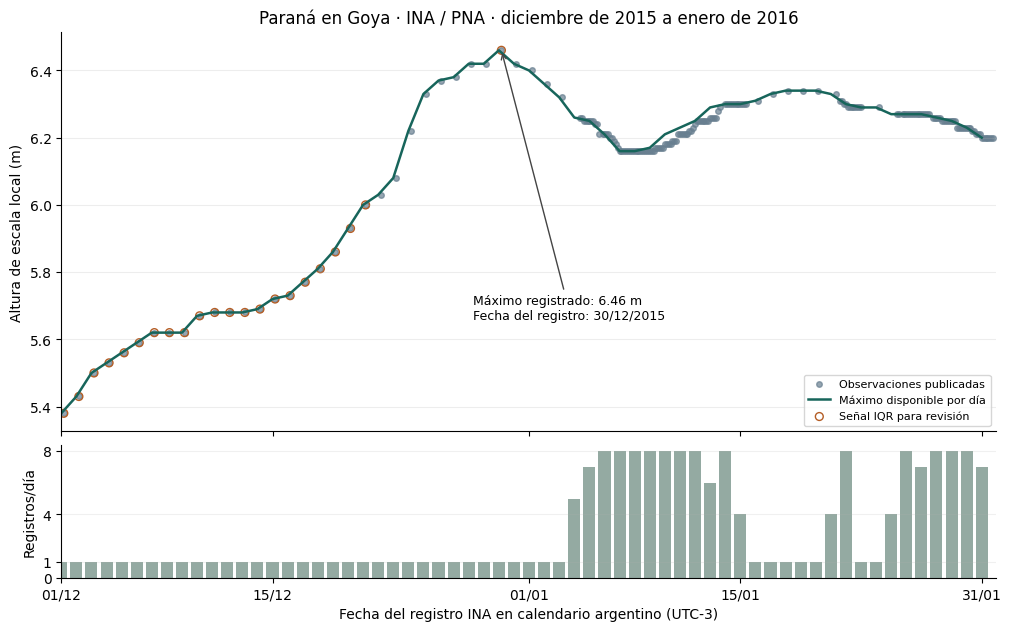

In [8]:
maximo = float(serie.max())
fila_max = limpios.loc[limpios['altura_m'].idxmax()]
fig, (ax, ax_n) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}, layout='constrained')
ax.scatter(limpios['marca_registro_art'], limpios['altura_m'], s=16, color='#687f90', alpha=.7,
           label='Observaciones publicadas')
ax.plot(diario.index, diario['max_disponible_m'], lw=1.8, color='#17655b', label='Máximo disponible por día')
ax.scatter(marcados['marca_registro_art'], marcados['altura_m'], s=32, facecolors='none',
           edgecolors='#b45d25', label='Señal IQR para revisión')
ax.annotate(f"Máximo registrado: {maximo:.2f} m\nFecha del registro: {fila_max['marca_registro_art']:%d/%m/%Y}",
    xy=(fila_max['marca_registro_art'], maximo), xytext=(.44, .28), textcoords='axes fraction',
    arrowprops={'arrowstyle': '->', 'color': '#444'}, fontsize=9)
ax.set(ylabel='Altura de escala local (m)', title='Paraná en Goya · INA / PNA · diciembre de 2015 a enero de 2016')
ax.grid(axis='y', alpha=.22)
ax.legend(loc='lower right', fontsize=8)
ax_n.bar(diario.index, diario['n_registros'], width=.8, color='#94aaa2')
ax_n.set(ylabel='Registros/día', xlabel='Fecha del registro INA en calendario argentino (UTC-3)', yticks=[0, 1, 4, 8])
ax_n.set_xlim(inicio, fin - pd.Timedelta(hours=1))
ax_n.set_xticks(pd.to_datetime(['2015-12-01','2015-12-15','2016-01-01','2016-01-15','2016-01-31']).tz_localize(ZONA))
ax_n.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m', tz=serie.index.tz))
ax_n.grid(axis='y', alpha=.18)
fig.savefig(salidas/'serie_y_muestreo.png', dpi=180, bbox_inches='tight')
plt.show()

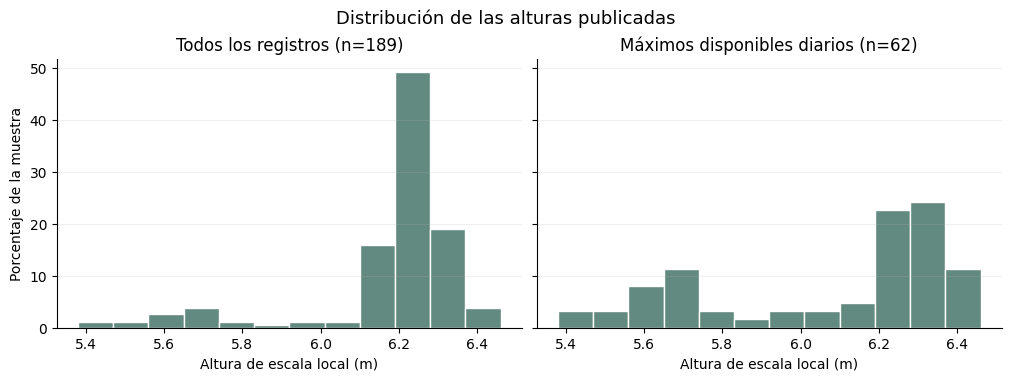

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), sharex=True, sharey=True, layout='constrained')
bordes = np.linspace(serie.min(), serie.max(), 13)
muestras = [(serie, f'Todos los registros (n={len(serie)})'),
    (diario['max_disponible_m'].dropna(), f'Máximos disponibles diarios (n={diario.max_disponible_m.count()})')]
for ax, (valores, titulo) in zip(axes, muestras):
    ax.hist(valores, bins=bordes, weights=np.full(len(valores), 100/len(valores)),
            color='#638a80', edgecolor='white')
    ax.set(title=titulo, xlabel='Altura de escala local (m)')
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Porcentaje de la muestra')
fig.suptitle('Distribución de las alturas publicadas', fontsize=13)
fig.savefig(salidas/'distribuciones.png', dpi=180, bbox_inches='tight')
plt.show()

In [10]:
CAPTURAS_METEO = {'lluvia_era5': {'url': 'https://archive-api.open-meteo.com/v1/archive?latitude=-29.14376844&longitude=-59.27303952&start_date=2015-12-01&end_date=2016-01-31&timezone=America%2FArgentina%2FBuenos_Aires&cell_selection=nearest&models=era5&daily=precipitation_sum', 'descarga_utc': '2026-11-08T18:44:28.323489+00:00', 'http_status': 200, 'sha256': 'd350079a15984284cb091b0994d5c119a9d7d966f637ab940ae645af8410581e', 'bytes': 1422, 'captura_gzip_base64': 'H4sIAAAAAAACA5WTTW+cMBCG/4vP4HjG2EBu20tPufUWRYjsOpGlBSI+IqXR/veOYcO+jXrpZaTHnnfmQRaf6tzOcV5OQd3nXGt2mToP/evXkduOXkMfRmkc+jl2oekmdW+0JSpqW5XW1Z5qKjK1zMdmeHmZwtxM4Tj0J+nLyVTGZCoFfw+9DFWHLozx2N4dRpk7x769+7GEfpiaQxzDpG69Tfv8PIb3uG6W4M+HX7mV+3AO79cza7QMP7Xx/NEsfZxl4+eal/Y4DZU3JIG3MRzjW5zXUDMtndx2nbpck7fMo2JDLifO19wOjGARCgSH4BFKhAqhBiCDgAaEBoQGhAaEBoQGhAaEBoQGjAaMBowGjAaMBowGjAaMBowGjAYWDezVwMt77E+yASNYhALBIXiEEqFCqAG+nmQDNCA0IDQgNCA0IDQgNCA0IDRgNGA0YDRgNGA0YDRgNGA0YDRgNLBoIE/y9M8/6pG0NxlrZ7JS1yaTPzMVToV2lOJTyw251FXKSSOZv6+qFHSs7X4obHUphz6tKOqt3+EO0kUqqZO2kMe42afRqklp+zfDa7GIBYz53+LSIv42cFUkTl9jRPnpcvkDSUUThY4FAAA='}, 'suelo_era5_land': {'url': 'https://archive-api.open-meteo.com/v1/archive?latitude=-29.14376844&longitude=-59.27303952&start_date=2015-12-01&end_date=2016-01-31&timezone=America%2FArgentina%2FBuenos_Aires&cell_selection=nearest&models=era5_land&daily=soil_moisture_0_to_7cm_mean', 'descarga_utc': '2026-11-08T18:44:32.883925+00:00', 'http_status': 200, 'sha256': 'd0e916e0402c6be9b88c3ca612b647a3930697c4625655646009fee47de93ef0', 'bytes': 1510, 'captura_gzip_base64': 'H4sIAAAAAAACA4WTTW7bMBCF78K1bHOGpERl52666q67IBAUmwkI6AeQ5ABt4FP1Bj1ZyaFjv10FeOA3P4/fiNCnGvotbpdzUE87bve6TY+v1DBP719p1+45p12l3sMUljQwT1scQzeu6knvta3JmFTXribHxtpKXbZTN7+9rWHr1nCap3Pq3JH2Wlcqj/6ep2StjmNY4qk/HJfkvMWpP3y7hGleu2NcwqoevV3/+rqEjyhnp8HvP37uTKqHIXzcciaRVOrcx+FXd5nilk78lPnUHtfZ15rSwDrHoRvnuG6XJXS62+auOY3dGPpsO/79c0g/db0ZPSyeFWtyO+Kd2NwFozAoLAqHokbRoPAoWhCkUSABIQEhASEBIQEhASEBIQEhASMBIwEjASMBIwEjASMBIwEjASOBQQJzI6jTfdyvpAhGYVBYFA5FjaJB4VG0IL6upAgkICQgJCAkICQgJCAkICQgJGAkYCRgJGAkYCRgJGAkYCRgJGAkMEiQruTlPx/Ys94bdlWKhnJsOce6zdE2kpcqSUYbyZSq9JP0kJUpnaOXfFPn6GTW5v+29HhxqO09Wl3OFc9W3BqZcl5mJTotncLWikMjDq6QFH7JNMVHTvdlF/F09sHM4kn1Y6NSNcKvcz/7XOU6d7LLPSxbM0teZlnnSEJOQsXFuWwtb5Wlyh42cv7lev0HHrnB5OYFAAA='}}
productos = {}
metadatos_meteo = []
configuracion = {
    'lluvia_era5': ('ERA5', 'precipitation_sum', 'mm', '0,25°'),
    'suelo_era5_land': ('ERA5-Land', 'soil_moisture_0_to_7cm_mean', 'm³/m³', '0,1°')}
for clave, meta in CAPTURAS_METEO.items():
    original = gzip.decompress(base64.b64decode(meta['captura_gzip_base64']))
    assert hashlib.sha256(original).hexdigest() == meta['sha256']
    if MODO == 'api':
        with urllib.request.urlopen(meta['url'], timeout=45) as respuesta:
            assert respuesta.status == 200
            original = respuesta.read()
        descarga = datetime.now(timezone.utc).isoformat()
    else:
        descarga = meta['descarga_utc']
    producto = json.loads(original)
    modelo, variable, unidad, resolucion = configuracion[clave]
    assert producto['utc_offset_seconds'] == -10800
    assert producto['daily_units'][variable] == unidad
    productos[clave] = producto
    (salidas/f'{clave}_original.json').write_bytes(original)
    metadatos_meteo.append({
        'producto': modelo, 'tipo': 'reanálisis', 'variable': variable,
        'unidad': unidad, 'resolucion': resolucion,
        'latitud_celda': producto['latitude'], 'longitud_celda': producto['longitude'],
        'descarga_utc': descarga,
        'sha256': hashlib.sha256(original).hexdigest(), 'url': meta['url']})
metadatos_meteo = pd.DataFrame(metadatos_meteo)
display(metadatos_meteo.drop(columns=['url','sha256']))
for _, fila in metadatos_meteo.iterrows():
    print(f"{fila['producto']} | URL: {fila['url']} | SHA-256: {fila['sha256']}")
metadatos_meteo.to_json(salidas/'metadatos_meteo.json', orient='records', force_ascii=False, indent=2)

,producto,tipo,variable,unidad,resolucion,latitud_celda,longitud_celda,descarga_utc
0,ERA5,reanálisis,precipitation_sum,mm,"0,25°",-29.250000,-59.250000,2026-11-08T18:44:28.323489+00:00
1,ERA5-Land,reanálisis,soil_moisture_0_to_7cm_mean,m³/m³,"0,1°",-29.099998,-59.299995,2026-11-08T18:44:32.883925+00:00


ERA5 | URL: https://archive-api.open-meteo.com/v1/archive?latitude=-29.14376844&longitude=-59.27303952&start_date=2015-12-01&end_date=2016-01-31&timezone=America%2FArgentina%2FBuenos_Aires&cell_selection=nearest&models=era5&daily=precipitation_sum | SHA-256: d350079a15984284cb091b0994d5c119a9d7d966f637ab940ae645af8410581e
ERA5-Land | URL: https://archive-api.open-meteo.com/v1/archive?latitude=-29.14376844&longitude=-59.27303952&start_date=2015-12-01&end_date=2016-01-31&timezone=America%2FArgentina%2FBuenos_Aires&cell_selection=nearest&models=era5_land&daily=soil_moisture_0_to_7cm_mean | SHA-256: d0e916e0402c6be9b88c3ca612b647a3930697c4625655646009fee47de93ef0


In [11]:
meteo = pd.DataFrame(index=calendario)
calidad_meteo = []
baches_meteo = []
for clave, nombre in [('lluvia_era5', 'lluvia_mm_dia'), ('suelo_era5_land', 'humedad_0_7_m3m3')]:
    variable = configuracion[clave][1]
    tabla = pd.DataFrame(productos[clave]['daily'])
    fechas = pd.to_datetime(tabla['time'], errors='coerce')
    assert fechas.notna().all(), 'Fecha meteorológica inválida.'
    assert not fechas.duplicated().any(), 'Fecha meteorológica duplicada: revisar fuente.'
    tabla.index = pd.DatetimeIndex(fechas).tz_localize(ZONA)
    assert tabla.index.isin(calendario).all(), 'La fuente incluye fechas fuera del período.'
    faltan_fechas = calendario.difference(tabla.index)
    valores = pd.to_numeric(tabla[variable], errors='coerce').reindex(calendario)
    no_finitos = valores.notna() & ~np.isfinite(valores)
    imposible = valores.lt(0) if clave == 'lluvia_era5' else (valores.lt(0) | valores.gt(1))
    valores_validos = valores.mask(no_finitos | imposible)
    meteo[nombre] = valores_validos
    mascara = valores_validos.isna()
    grupos = (mascara != mascara.shift()).cumsum()
    for _, tramo in valores_validos[mascara].groupby(grupos[mascara]):
        baches_meteo.append({'variable': nombre, 'desde': tramo.index.min().strftime('%Y-%m-%d'),
                            'hasta': tramo.index.max().strftime('%Y-%m-%d'), 'dias': len(tramo)})
    calidad_meteo.append({'variable': nombre, 'fechas_esperadas': len(calendario),
        'fechas_omitidas': len(faltan_fechas), 'nulos_o_no_numericos_en_fuente': int(pd.to_numeric(tabla[variable], errors='coerce').isna().sum()),
        'no_finitos': int(no_finitos.sum()), 'fuera_limite_fisico': int(imposible.sum()),
        'dias_no_utilizables': int(mascara.sum()), 'ceros_publicados': int(valores.eq(0).sum())})
    print(nombre, '| Fechas no utilizables:', [f.strftime('%d/%m/%Y') for f in calendario[mascara]])
calidad_meteo = pd.DataFrame(calidad_meteo).set_index('variable')
display(calidad_meteo)
print('Baches consecutivos:', baches_meteo if baches_meteo else '0 en ambas series; no hay períodos sin dato.')
print('No se interpolaron valores ni se rellenaron nulos con cero.')
def resumen_meteo(s):
    return pd.Series({'n': s.count(), 'mínimo': s.min(), 'media': s.mean(),
        'P05': s.quantile(.05), 'P25': s.quantile(.25), 'P50': s.quantile(.5),
        'P75': s.quantile(.75), 'P95': s.quantile(.95), 'máximo': s.max()})
estadisticas_meteo = meteo.apply(resumen_meteo)
display(estadisticas_meteo.round(3))
print('Lluvia: mm por día; humedad: m³/m³. Percentiles lineales del período, no climatológicos.')
lluvia_mensual = meteo['lluvia_mm_dia'].resample('MS').sum(min_count=1)
# Sólo se informa un total mensual cuando están disponibles todos los días del mes.
completo = meteo['lluvia_mm_dia'].resample('MS').count().eq(meteo['lluvia_mm_dia'].resample('MS').size())
lluvia_mensual = lluvia_mensual.where(completo)
display(lluvia_mensual.rename('Precipitación mensual disponible (mm)').to_frame())
meteo.to_csv(salidas/'goya_meteorologia_diaria.csv', index_label='fecha_art')
calidad_meteo.to_csv(salidas/'goya_calidad_meteo.csv')
estadisticas_meteo.to_csv(salidas/'goya_estadisticas_meteo.csv')
(salidas/'goya_baches_meteo.json').write_text(json.dumps(baches_meteo, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(meteo) == 62 and meteo.index.equals(diario.index)
assert np.allclose(meteo.quantile([.05,.25,.5,.75,.95]).to_numpy(),
    np.nanpercentile(meteo.to_numpy(), [5,25,50,75,95], axis=0, method='linear'), equal_nan=True)
print('Comprobaciones de las series meteorológicas: OK.')

lluvia_mm_dia | Fechas no utilizables: []
humedad_0_7_m3m3 | Fechas no utilizables: []


,fechas_esperadas,fechas_omitidas,nulos_o_no_numericos_en_fuente,no_finitos,fuera_limite_fisico,dias_no_utilizables,ceros_publicados
variable,,,,,,,
lluvia_mm_dia,62,0,0,0,0,0,29
humedad_0_7_m3m3,62,0,0,0,0,0,0


Baches consecutivos: 0 en ambas series; no hay períodos sin dato.
No se interpolaron valores ni se rellenaron nulos con cero.


,lluvia_mm_dia,humedad_0_7_m3m3
n,62.000,62.000
mínimo,0.000,0.193
media,5.324,0.333
P05,0.000,0.216
P25,0.000,0.314
P50,0.100,0.346
P75,2.425,0.368
P95,30.840,0.399
máximo,56.900,0.414


Lluvia: mm por día; humedad: m³/m³. Percentiles lineales del período, no climatológicos.


,Precipitación mensual disponible (mm)
2015-12-01 00:00:00-03:00,264.6
2016-01-01 00:00:00-03:00,65.5


Comprobaciones de las series meteorológicas: OK.


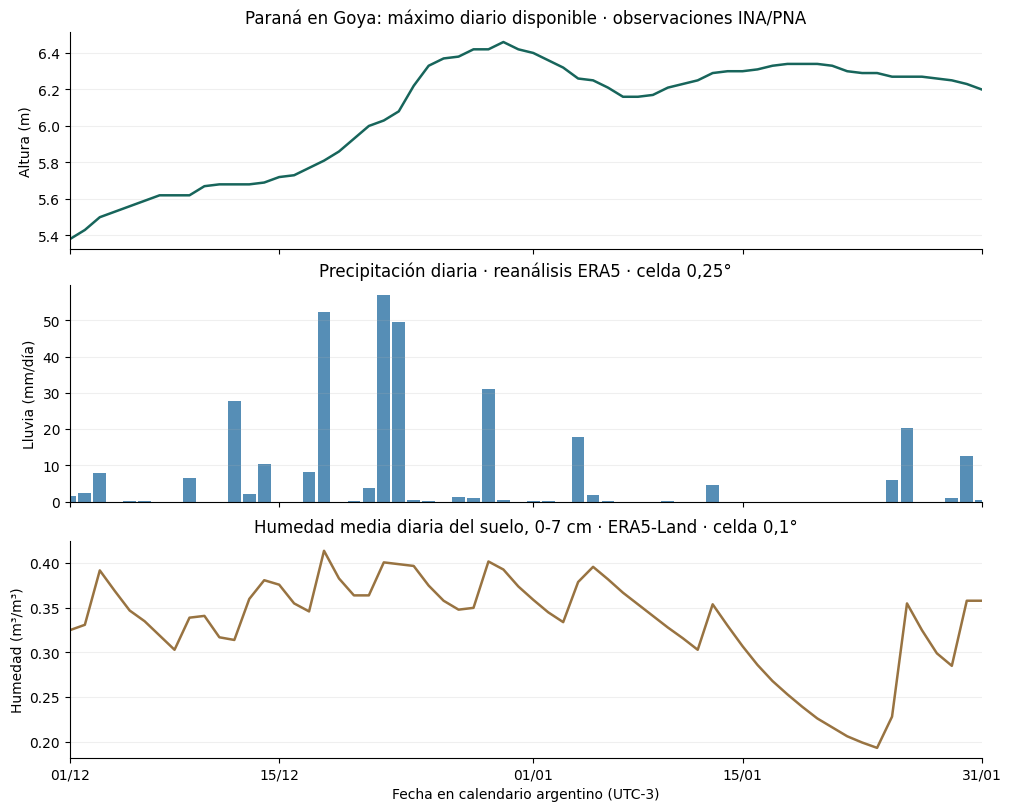

En estas celdas, ERA5 estima **264.6 mm en diciembre** y
**65.5 mm en enero**. El máximo diario es **56.9 mm**
el **22/12/2015**. La humedad superficial ERA5-Land varía entre
**0.193 y 0.414 m³/m³**; sus medias de diciembre y enero son
**0.360 y 0.306 m³/m³**.

En enero se observa un secado de la capa superficial durante el tramo con poca lluvia local estimada,
mientras el río permanece por encima de su nivel inicial. Esta diferencia es relevante para el manejo
ganadero: la humedad superficial y la altura fluvial describen procesos y escalas distintos.
No demuestra por sí sola un desfase causal ni permite predecir anegamiento de un lote.
Sin una climatología no se afirma que los acumulados sean anómalos.

In [12]:
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout='constrained')
axs[0].plot(diario.index, diario['max_disponible_m'], color='#17655b', lw=1.8)
axs[0].set(ylabel='Altura (m)', title='Paraná en Goya: máximo diario disponible · observaciones INA/PNA')
axs[1].bar(meteo.index, meteo['lluvia_mm_dia'], color='#568eb6', width=.85)
axs[1].set(ylabel='Lluvia (mm/día)', title='Precipitación diaria · reanálisis ERA5 · celda 0,25°')
axs[2].plot(meteo.index, meteo['humedad_0_7_m3m3'], color='#987341', lw=1.8)
axs[2].set(ylabel='Humedad (m³/m³)', title='Humedad media diaria del suelo, 0-7 cm · ERA5-Land · celda 0,1°',
           xlabel='Fecha en calendario argentino (UTC-3)')
for ax in axs:
    ax.grid(axis='y', alpha=.2)
axs[2].set_xlim(inicio, fin-pd.Timedelta(days=1))
axs[2].set_xticks(pd.to_datetime(['2015-12-01','2015-12-15','2016-01-01','2016-01-15','2016-01-31']).tz_localize(ZONA))
axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m', tz=serie.index.tz))
fig.savefig(salidas/'rio_lluvia_suelo.png', dpi=180, bbox_inches='tight')
plt.show()

ll = meteo['lluvia_mm_dia']; sm = meteo['humedad_0_7_m3m3']
resultados_meteo = {
    'lluvia_total_dic_mm': float(lluvia_mensual.iloc[0]),
    'lluvia_total_ene_mm': float(lluvia_mensual.iloc[1]),
    'lluvia_maxima_diaria_mm': float(ll.max()), 'lluvia_maxima_fecha': ll.idxmax().strftime('%Y-%m-%d'),
    'humedad_min_m3m3': float(sm.min()), 'humedad_min_fecha': sm.idxmin().strftime('%Y-%m-%d'),
    'humedad_max_m3m3': float(sm.max()), 'humedad_max_fecha': sm.idxmax().strftime('%Y-%m-%d'),
    'humedad_media_dic_m3m3': float(sm.loc['2015-12'].mean()),
    'humedad_media_ene_m3m3': float(sm.loc['2016-01'].mean()),
    'dias_lluvia_cero': int(ll.eq(0).sum()), 'dias_meteo_no_utilizables': int(meteo.isna().sum().sum())}
(salidas/'resumen_meteo.json').write_text(json.dumps(resultados_meteo, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f"""En estas celdas, ERA5 estima **{lluvia_mensual.iloc[0]:.1f} mm en diciembre** y
**{lluvia_mensual.iloc[1]:.1f} mm en enero**. El máximo diario es **{ll.max():.1f} mm**
el **{ll.idxmax():%d/%m/%Y}**. La humedad superficial ERA5-Land varía entre
**{sm.min():.3f} y {sm.max():.3f} m³/m³**; sus medias de diciembre y enero son
**{sm.loc['2015-12'].mean():.3f} y {sm.loc['2016-01'].mean():.3f} m³/m³**.

En enero se observa un secado de la capa superficial durante el tramo con poca lluvia local estimada,
mientras el río permanece por encima de su nivel inicial. Esta diferencia es relevante para el manejo
ganadero: la humedad superficial y la altura fluvial describen procesos y escalas distintos.
No demuestra por sí sola un desfase causal ni permite predecir anegamiento de un lote.
Sin una climatología no se afirma que los acumulados sean anómalos."""))

In [13]:
primero, ultimo = limpios.iloc[0], limpios.iloc[-1]
texto = f"""
La altura publicada pasa de **{primero['altura_m']:.2f} m** (fecha del registro: {primero['marca_registro_art']:%d/%m/%Y})
a un máximo disponible de **{maximo:.2f} m** ({fila_max['marca_registro_art']:%d/%m/%Y}),
y cierra la ventana en **{ultimo['altura_m']:.2f} m** ({ultimo['marca_registro_art']:%d/%m/%Y}).
El aumento entre el primer registro y el máximo disponible es **{maximo-primero['altura_m']:.2f} m**.
La media de los {len(serie)} registros es **{serie.mean():.3f} m**; la media de los
{diario.max_disponible_m.count()} máximos disponibles diarios es **{diario.max_disponible_m.mean():.3f} m**.

Se observa un ascenso durante diciembre y niveles que al terminar enero continúan por encima del inicio de la ventana.
Esto describe persistencia de alturas elevadas dentro de la muestra, sin demostrar por sí solo daños en campos.

**Sorpresas del análisis:** hay registros todos los días, pero la frecuencia cambia entre
{diario.n_registros.min()} y {diario.n_registros.max()} por fecha. Además, el IQR señala {len(marcados)} registros,
entre ellos parte del ascenso y el pico: aplicar un borrado automático distorsionaría la descripción del episodio.

**Limitaciones:** no hay una frecuencia intradiaria esperada confirmada ni una validación independiente de las mediciones.
La altura de escala no equivale a profundidad de agua en un establecimiento. No se analizaron lluvia en la cuenca aguas arriba,
caudal, topografía ni afectaciones documentadas; no se atribuyen causas meteorológicas locales, no se estiman tiempos
de llegada ni se calibran umbrales para ganado. La ventana de 62 días no permite inferir recurrencias, tendencias
climáticas o capacidad predictiva. Las marcas horarias son de registro y no confirman horas efectivas de medición.
"""
display(Markdown(texto))


La altura publicada pasa de **5.38 m** (fecha del registro: 01/12/2015)
a un máximo disponible de **6.46 m** (30/12/2015),
y cierra la ventana en **6.20 m** (31/01/2016).
El aumento entre el primer registro y el máximo disponible es **1.08 m**.
La media de los 189 registros es **6.180 m**; la media de los
62 máximos disponibles diarios es **6.076 m**.

Se observa un ascenso durante diciembre y niveles que al terminar enero continúan por encima del inicio de la ventana.
Esto describe persistencia de alturas elevadas dentro de la muestra, sin demostrar por sí solo daños en campos.

**Sorpresas del análisis:** hay registros todos los días, pero la frecuencia cambia entre
1 y 8 por fecha. Además, el IQR señala 22 registros,
entre ellos parte del ascenso y el pico: aplicar un borrado automático distorsionaría la descripción del episodio.

**Limitaciones:** no hay una frecuencia intradiaria esperada confirmada ni una validación independiente de las mediciones.
La altura de escala no equivale a profundidad de agua en un establecimiento. No se analizaron lluvia en la cuenca aguas arriba,
caudal, topografía ni afectaciones documentadas; no se atribuyen causas meteorológicas locales, no se estiman tiempos
de llegada ni se calibran umbrales para ganado. La ventana de 62 días no permite inferir recurrencias, tendencias
climáticas o capacidad predictiva. Las marcas horarias son de registro y no confirman horas efectivas de medición.


In [14]:
limpios.to_csv(salidas/'goya_registros_revisados.csv', index=False)
diario.to_csv(salidas/'goya_resumen_diario.csv', index_label='fecha_registro_art')
estadisticas.to_csv(salidas/'goya_estadisticas.csv', index_label='estadistico')
intervalos_fechas.to_csv(salidas/'goya_intervalos_mayores_24h.csv', index=False)
resumen = dict(calidad, dias_calendario=len(diario), dias_vacios=len(dias_vacios),
    registros_dia_min=int(diario.n_registros.min()), registros_dia_max=int(diario.n_registros.max()),
    n_intervalos_mayores_24h=len(intervalos_largos), n_iqr=len(marcados),
    limite_iqr_inferior=limite_inferior, limite_iqr_superior=limite_superior,
    minimo_m=float(serie.min()), maximo_m=maximo, media_registros_m=float(serie.mean()),
    media_maximos_diarios_m=float(diario.max_disponible_m.mean()),
    percentiles_registros={str(q):float(serie.quantile(q)) for q in [.05,.25,.5,.75,.95]},
    maximo_fecha_registro=fila_max.marca_registro_art.strftime('%Y-%m-%d'),
    hora_medicion_confirmada=False, ultimo_valor_m=float(ultimo.altura_m),
    fecha_descarga_utc=fecha_descarga, sha256=huella, url_fuente=URL,
    intervalos=[{'desde_fecha': r.marca_anterior_art.strftime('%Y-%m-%d'),
                 'hasta_fecha': r.marca_registro_art.strftime('%Y-%m-%d'),
                 'horas_entre_marcas':float(r.intervalo_h)} for _,r in intervalos_largos.iterrows()])
(salidas/'resumen_resultados.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
assert diario.n_registros.sum() == len(limpios)
assert len(diario) == (fin-inicio).days
assert not limpios.marca_registro_utc.duplicated().any()
assert limpios.marca_registro_utc.is_monotonic_increasing
assert limpios.marca_registro_art.between(inicio, fin, inclusive='left').all()
assert np.isfinite(limpios.altura_m).all()
assert diario.loc[diario.n_registros.eq(0), 'max_disponible_m'].isna().all()
assert np.allclose(serie.quantile([.05,.25,.5,.75,.95]),
                   np.percentile(serie.to_numpy(), [5,25,50,75,95], method='linear'))
print('Comprobaciones de coherencia: OK. Resultados guardados en', salidas)

Comprobaciones de coherencia: OK. Resultados guardados en salidas_goya
